# Netflix Content Analysis and Recommendation System

# 1. Business Understanding
# 1.1 Project Objective

Analyze Netflix's content catalogue to identify useful patterns and build a content-based recommendation system that suggests similar movies and TV shows.

# 1.2 Problem Statement

With many titles available on Netflix, finding similar content can be challenging. This project uses title metadata, genres, and descriptions to explore the catalogue and recommend related titles.

# 1.3 Technical Approach

Use Python and Pandas for data cleaning and analysis, visualization for exploring trends, and TF-IDF with cosine similarity to build the content-based recommendation system. The model will later be evaluated, and a Streamlit app will demonstrate its recommendations.

# 1.4 Key Challenges

1. Missing or inconsistent data.

2. Incomplete information about some titles.

3. No viewer ratings or watch history to measure actual user preferences.

4. Evaluating recommendation relevance without real user feedback.

# 1.5 Success Metrics

1. A cleaned and reliable dataset.

2. Clear, evidence-based findings about Netflix's catalogue.

3. Relevant recommendations based on similarities between titles.

4. A working app that displays recommendations correctly.

# 1.6 Expected Outcomes

A documented analysis, a content-based recommendation model, and an interactive Streamlit application demonstrating the results.

# 1.7 Business Questions

1. Content Distribution: How are movies and TV shows distributed across Netflix's catalogue?

1. Content Trends: How has the number of titles released changed over the years?

2. Content Ratings: Which maturity ratings are most common in the catalogue?

3. Content Categories: Which genres appear most frequently?

4. Content Availability: Which countries contribute the most titles, based on the available country information?

5. Content Recommendations: Can we use title genres and descriptions to recommend movies or TV shows similar to a selected title?

# 2. Data Understanding

# 2.1 Data Source

The project uses the Netflix Movies and TV Shows dataset by Shivam Bansal, available on Kaggle.

Dataset link: https://www.kaggle.com/datasets/shivamb/netflix-shows

# 2.2 Initial Data Inspection

Before cleaning or modelling, we need to understand the dataset's structure, size, column names, data types, and quality.

We will:

1. Load the dataset into Pandas.

2. Inspect the first and last few rows.

3. Check the number of rows and columns.

4. Review column names and data types.

5. Identify missing values and duplicate records.

6. Examine summary statistics where applicable.

# 2.3 Understanding the Variables

We will examine what each column represents and determine how it can support our business questions and recommendation system.

# 2.4 Data Quality Assessment

We will investigate missing values, duplicates, inconsistent formats, and any limitations that could affect our analysis or recommendations.

In [2]:
# importing libraries
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing and recommendation system
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Train-test splitting and evaluation utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [7]:
import os

print(os.getcwd())

c:\Users\User\Documents\Netflix_project\notebooks


In [3]:
#  loading the csv file into a pandas dataframe
df = pd.read_csv("../data/netflix_titles.csv")
df[:5]


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# checking last values
df.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [5]:
# checking data types 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [12]:
# checking statistical summary
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
#check on duplicate values
df.duplicated().sum()

0

In [8]:
# checking missing values 
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [9]:
#calculating the percentage 
missing_percentage = (df.isnull().mean() * 100).round(2)

missing_percentage.sort_values(ascending=False)

director        29.91
country          9.44
cast             9.37
date_added       0.11
rating           0.05
duration         0.03
show_id          0.00
type             0.00
title            0.00
release_year     0.00
listed_in        0.00
description      0.00
dtype: float64

In [16]:
#inspecting column duration
df[df["duration"].isnull()]#["type"].value_counts()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [19]:
#check rating colum
df[df['rating'].isnull()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5989,s5990,Movie,13TH: A Conversation with Oprah Winfrey & Ava ...,NaN,"Oprah Winfrey, Ava DuVernay",NaN,"January 26, 2017",2017,NaN,37 min,Movies,Oprah Winfrey sits down with director Ava DuVe...
6827,s6828,TV Show,Gargantia on the Verdurous Planet,NaN,"Kaito Ishikawa, Hisako Kanemoto, Ai Kayano, Ka...",Japan,"December 1, 2016",2013,NaN,1 Season,"Anime Series, International TV Shows","After falling through a wormhole, a space-dwel..."
7312,s7313,TV Show,Little Lunch,NaN,"Flynn Curry, Olivia Deeble, Madison Lu, Oisín ...",Australia,"February 1, 2018",2015,NaN,1 Season,"Kids' TV, TV Comedies","Adopting a child's perspective, this show take..."
7537,s7538,Movie,My Honor Was Loyalty,Alessandro Pepe,"Leone Frisa, Paolo Vaccarino, Francesco Miglio...",Italy,"March 1, 2017",2015,NaN,115 min,Dramas,"Amid the chaos and horror of World War II, a c..."


In [20]:
df[df["rating"].isnull()][
    ["title", "type", "release_year", "rating", "duration"]
]

,title,type,release_year,rating,duration
5989,13TH: A Conversation with Oprah Winfrey & Ava ...,Movie,2017,NaN,37 min
6827,Gargantia on the Verdurous Planet,TV Show,2013,NaN,1 Season
7312,Little Lunch,TV Show,2015,NaN,1 Season
7537,My Honor Was Loyalty,Movie,2015,NaN,115 min


## Exploratory Data Analysis.

## 1. Univariate Analysis
It examines one variable at a time.

In [ ]:
#checking on the distribution of the type column and converting to percentage
(df["type"].value_counts(normalize=True)* 100).round(2)

Movie      69.62
TV Show    30.38
Name: type, dtype: float64

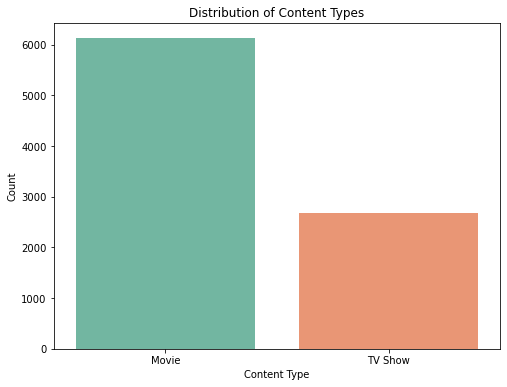

In [28]:
# visualizing the distribution of the type column
plt.figure(figsize=(8,6))
sns.countplot(data=df, x="type", palette="Set2")
plt.title("Distribution of Content Types")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()


Observation: Movie has a higher contribution on netflix than the tv shows. This shows 69.6% of people watch movies over TV shows which comes next with 30%.

In [41]:
# inspecting rating column
print(df["rating"].isna().sum())       # missing values

print(df["rating"].nunique())             # number of categories
print(df["rating"].value_counts())        # counts
print(df["rating"].value_counts(normalize=True).mul(100).round(2))  # percentages

4
17
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: rating, dtype: int64
TV-MA       36.43
TV-14       24.54
TV-PG        9.80
R            9.08
PG-13        5.57
TV-Y7        3.79
TV-Y         3.49
PG           3.26
TV-G         2.50
NR           0.91
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
74 min       0.01
84 min       0.01
66 min       0.01
Name: rating, dtype: float64


In [42]:
#cleaning 
valid_ratings = ["TV-MA", "TV-14", "TV-PG", "R", "TV-Y7", "TV-Y",
                 "PG-13", "PG", "TV-G", "G", "NR", "TV-Y7-FV",
                 "NC-17", "UR"]
rating_clean = df.loc[df["rating"].isin(valid_ratings), "rating"]

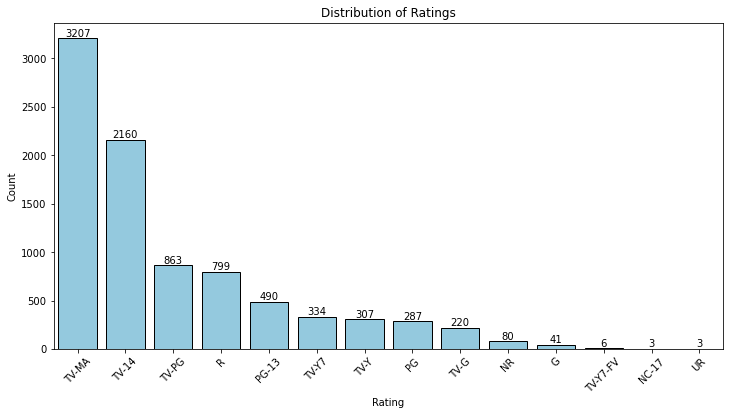

In [47]:
#visualising
plt.figure(figsize=(12,6))
order= rating_clean.value_counts().index
ax = sns.countplot(x=rating_clean, order=order,
                   color= "skyblue", edgecolor="black")
#add count labels on top of bars
for p in ax.patches:
   ax.annotate(int(p.get_height()),
               (p.get_x() + p.get_width() / 2, p.get_height()),
               ha="center", va="bottom")

plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

Observation: The netflix catalogue aimed at mature and teen viewers, with TV-MA and TV-14 as the clear leaders, while family and children’s content is a much smaller portion.

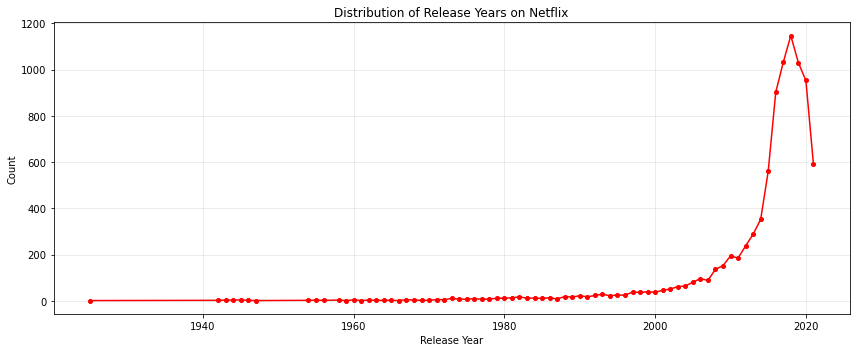

In [51]:
# analysis on release year
release_year_counts = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
release_year_counts.plot(kind='line', 
                         color='red', 
                         marker='o', 
                         markersize=4)
plt.title('Distribution of Release Years on Netflix')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Observation: This shows weighted toward recent releases, peaking around 2018, with very little content from before 2000. The latest year (2021) should be treated as incomplete rather than as evidence of a drop.